In [2]:
"""
Monte Carlo: Average nearest-neighbor distance among n random points on a 3D cube.

- Default: points are sampled uniformly INSIDE the unit cube [0,1]^3.
- Optionally: sample ON THE SURFACE of the cube (uniformly over faces).

If SciPy is available, the code uses cKDTree for O(n log n) nearest-neighbor queries.
Otherwise it falls back to a pure NumPy O(n^2) method (fine for moderate n).

Usage example (at bottom):
    python script.py
"""

from __future__ import annotations
import math
import numpy as np

In [4]:


# Optional SciPy acceleration
try:
    from scipy.spatial import cKDTree as _KDTree
    _HAS_SCIPY = True
except Exception:
    _HAS_SCIPY = False
    _KDTree = None


def sample_points_in_cube(n: int, low: float = 0.0, high: float = 1.0, rng=None) -> np.ndarray:
    """Uniform points INSIDE the cube [low, high]^3."""
    rng = np.random.default_rng(rng)
    return rng.uniform(low, high, size=(n, 3))


def sample_points_on_cube_surface(n: int, low: float = 0.0, high: float = 1.0, rng=None) -> np.ndarray:
    """
    Uniform points ON THE SURFACE of the cube.
    Each sample picks one of the 6 faces with equal probability and is uniform on that face.
    """
    rng = np.random.default_rng(rng)
    pts = rng.uniform(low, high, size=(n, 3))
    # Choose a face index 0..5 uniformly. Face pairs correspond to axes 0/1/2 × {low, high}.
    faces = rng.integers(0, 6, size=n)
    # axis is 0 for x-faces, 1 for y-faces, 2 for z-faces.
    axes = faces // 2
    highs = (faces % 2 == 1)
    # Pin the chosen axis coordinate to low or high
    pts[np.arange(n), axes] = np.where(highs, high, low)
    return pts


def nearest_neighbor_distances(points: np.ndarray, use_tree: bool = True) -> np.ndarray:
    """
    For each point, compute distance to its nearest OTHER point.
    Returns an array of shape (n,).
    """
    n = points.shape[0]
    if n < 2:
        return np.full(n, np.nan)

    if use_tree and _HAS_SCIPY:
        tree = _KDTree(points)
        # k=2 because the nearest neighbor includes the point itself at distance 0
        dists, _ = tree.query(points, k=2)
        return dists[:, 1]

    # Pure NumPy fallback (O(n^2) memory/time)
    # Compute pairwise distances via broadcasting
    diff = points[:, None, :] - points[None, :, :]
    D = np.sqrt(np.sum(diff * diff, axis=2))
    # Ignore self-distances by setting diagonal to +inf
    np.fill_diagonal(D, np.inf)
    return np.min(D, axis=1)


def avg_nearest_neighbor_distance(points: np.ndarray, use_tree: bool = True) -> float:
    """Average (mean) nearest-neighbor distance over all points."""
    d = nearest_neighbor_distances(points, use_tree=use_tree)
    return float(np.nanmean(d))


def monte_carlo_avg_nn(
    n: int,
    trials: int = 100,
    mode: str = "inside",  # "inside" or "surface"
    cube_low: float = 0.0,
    cube_high: float = 1.0,
    rng=None,
    use_tree: bool = True,
):
    """
    Run multiple trials. Each trial:
      1) sample n points (inside or on the surface of the cube),
      2) compute the average nearest-neighbor distance.

    Returns:
      samples   : (trials,) array of per-trial averages
      mean      : mean(samples)
      sem       : standard error of the mean
      ci_95     : (lo, hi) 95% CI using normal approximation
    """
    rng = np.random.default_rng(rng)
    sampler = sample_points_in_cube if mode == "inside" else sample_points_on_cube_surface

    samples = np.empty(trials, dtype=float)
    for t in range(trials):
        pts = sampler(n, low=cube_low, high=cube_high, rng=rng)
        samples[t] = avg_nearest_neighbor_distance(pts, use_tree=use_tree)

    mean = float(np.mean(samples))
    sem = float(np.std(samples, ddof=1) / math.sqrt(trials)) if trials > 1 else float("nan")
    z = 1.96
    ci_95 = (mean - z * sem, mean + z * sem) if trials > 1 else (float("nan"), float("nan"))
    return samples, mean, sem, ci_95




In [5]:
# Example: n points INSIDE the unit cube, repeated 'trials' times.
n = 800
trials = 200
seed = 42
result = []
for n in range(100, 2001, 150):
    samples, mean, sem, ci = monte_carlo_avg_nn(
        n=n,
        trials=trials,
        mode="inside",      # change to "surface" to sample on the cube surface
        cube_low=0.0,
        cube_high=1.0,
        rng=seed,
        use_tree=True,      # auto-uses SciPy cKDTree if available; falls back otherwise
    )
    result.append((n, samples, mean, sem, ci))


print(f"Trials: {trials}, n: {n} points per trial (mode='inside')")
print(f"Mean of average NN distance: {mean:.6f}")
print(f"SEM: {sem:.6f}")
print(f"95% CI: [{ci[0]:.6f}, {ci[1]:.6f}]")


Trials: 200, n: 1900 points per trial (mode='inside')
Mean of average NN distance: 0.045958
SEM: 0.000030
95% CI: [0.045900, 0.046016]


In [6]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'Average nearest-neighbor distance [$m$]')

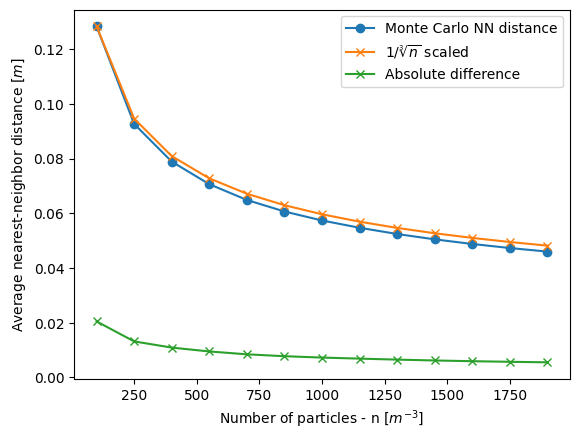

In [29]:
plt.plot([r[0] for r in result], [r[2] for r in result], marker='o', label='Monte Carlo NN distance')
plt.plot([r[0] for r in result],[1/r[0]**0.333*(result[0][2]/(1/result[0][0]**0.333)) for r in result],marker='x', label=r'$1/\sqrt[3]{n}$'+ " scaled")
plt.plot([r[0] for r in result],[abs(r[2]-1/r[0]**0.333/2) for r in result],marker='x', label='Absolute difference')
plt.legend()
plt.xlabel('Number of particles - n '+r'[$m^{-3}$]')
plt.ylabel('Average nearest-neighbor distance [$m$]')